In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.random.set_seed(42)
np.random.seed(42)

In [8]:
DATA_DIR=r"D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered"
print(os.listdir(DATA_DIR))

['train', 'validation', 'vectorize.py']


In [9]:
for root, dirs,files in os.walk(DATA_DIR):
    print(root,"->",len(files),"files")

D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered -> 1 files
D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\train -> 0 files
D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\train\cats -> 1000 files
D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\train\dogs -> 1000 files
D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\validation -> 0 files
D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\validation\cats -> 500 files
D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\validation\dogs -> 500 files


In [11]:
TRAIN_DIR=r"D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\train"
TEST_DIR=r"D:\dl-workspace\notebooks\datasets\cats_and_dogs_filtered\validation"

IMG_SIZE=(224,224)
BATCH=32

train_ds=keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.1,
    subset="training",
    image_size=IMG_SIZE,
    batch_size=BATCH,
    seed=42,
)
val_ds=keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.1,
    subset="validation",
    image_size=IMG_SIZE,
    batch_size=BATCH,
    seed=42
)
test_ds=keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH,
    shuffle=False
)

Found 2000 files belonging to 2 classes.
Using 1800 files for training.


Found 2000 files belonging to 2 classes.
Using 200 files for validation.
Found 1000 files belonging to 2 classes.


In [12]:
class_names=train_ds.class_names
num_classes=len(class_names)
print(class_names)
print(num_classes)

['cats', 'dogs']
2


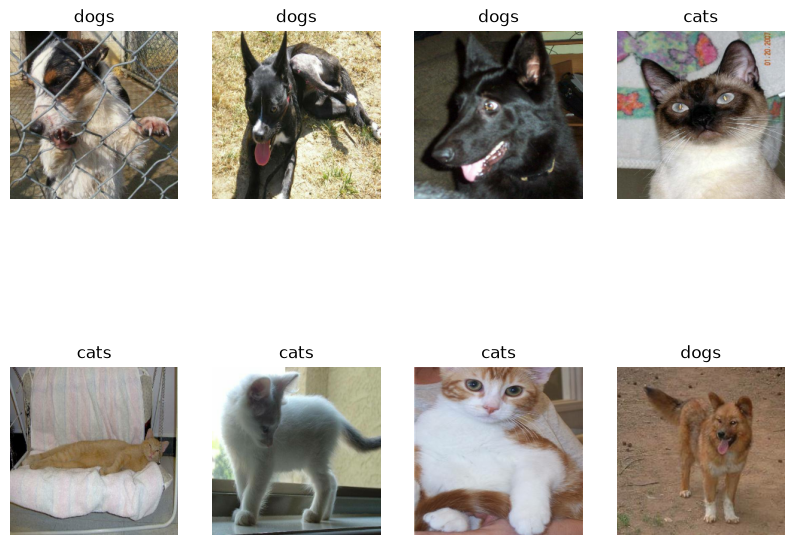

In [13]:
plt.figure(figsize=(10,8))

for images,labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2,4,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [16]:
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False 

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [19]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
model.compile(
    optimizer="adam", 
    loss="binary_crossentropy", 
    metrics=["accuracy"]
)
history = model.fit(
    train_ds, 
    validation_data=val_ds,
    epochs=10,
    verbose=1
)

Epoch 1/10


d:\dl-workspace\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 21s 312ms/step - accuracy: 0.9606 - loss: 0.0970 - val_accuracy: 0.9900 - val_loss: 0.0782
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 18s 322ms/step - accuracy: 0.9900 - loss: 0.0283 - val_accuracy: 0.9900 - val_loss: 0.0808
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 20s 351ms/step - accuracy: 0.9956 - loss: 0.0156 - val_accuracy: 0.9750 - val_loss: 0.1051
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 19s 335ms/step - accuracy: 0.9967 - loss: 0.0112 - val_accuracy: 0.9800 - val_loss: 0.1409
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 19s 342ms/step - accuracy: 0.9983 - loss: 0.0077 - val_accuracy: 0.9800 - val_loss: 0.1199
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 23s 398ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 0.9750 - val_loss: 0.1432
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 446ms/step - accuracy: 0.9989 - loss: 0.0039 - val_accuracy: 0.9800 - val_loss: 0.1336
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 23s 409ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.980

In [22]:
test_loss, test_acc=model.evaluate(test_ds)
print(test_loss)
print(test_acc)

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 207ms/step - accuracy: 0.9890 - loss: 0.0341
0.03408784419298172
0.9890000224113464
